---
title: Week 3 Challenge 1 KEY
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about using Pandas' plot method.

Use the notebook **Plotting with Pandas** as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## Tasks

### Task 1

Import the Pandas and Matplotlib PyPlot libraries.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### Task 2 

Load the `stocks` dataframe from Ploty Express (see code snippet below). This dataset contains stock prices for a set of companies (represented by their stock market symbols) over time.

```python
from plotly.express import data as pxdata
stocks = pxdata.stocks()
```

In [2]:
from plotly.express import data as pxdata
stocks = pxdata.stocks()
stocks.info()

<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    105 non-null    str    
 1   GOOG    105 non-null    float64
 2   AAPL    105 non-null    float64
 3   AMZN    105 non-null    float64
 4   FB      105 non-null    float64
 5   NFLX    105 non-null    float64
 6   MSFT    105 non-null    float64
dtypes: float64(6), str(1)
memory usage: 6.9 KB


### Task 3

Review the table -- is it Tidy or Wide?

In [3]:
stocks.head()

,date,GOOG,AAPL,AMZN,FB,NFLX,MSFT
0,2018-01-01,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2018-01-08,1.018172,1.011943,1.061881,0.959968,1.053526,1.015988
2,2018-01-15,1.032008,1.019771,1.053240,0.970243,1.049860,1.020524
3,2018-01-22,1.066783,0.980057,1.140676,1.016858,1.307681,1.066561
4,2018-01-29,1.008773,0.917143,1.163374,1.018357,1.273537,1.040708


**Answer**: The table appears to be wide, but it can be interpreted as tidy. 

The implicit unit of observation is the stock market itself. 

We are observing variables the reflect the stock market on a given day.

### Task 4

Use the `.plot()` method on the dataframe to create a line graph showing `date` on the x axis, the stocks' value on the y axis, and a separate plot for each stock symbol.

- Make the figure $10$ inches wide by $5$ inches tall.

**Answer**: The trick here is to set the date as the index.

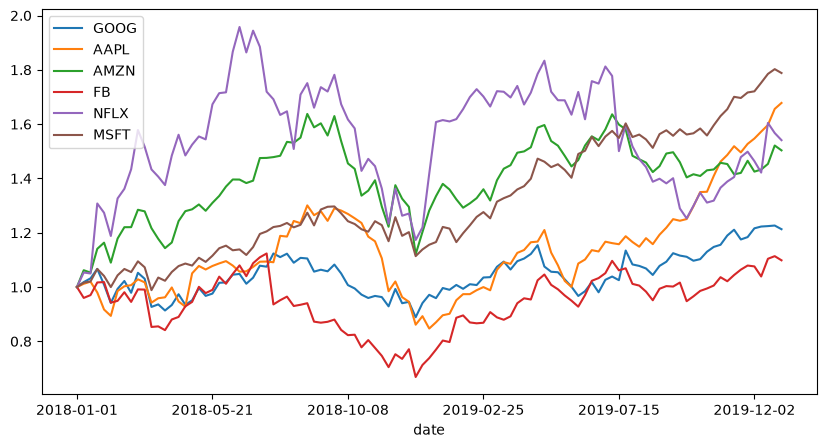

In [6]:
stocks1 = stocks.set_index('date')
stocks1.plot(rot=0, figsize=(10,5))
plt.show()

### Task 5

Plot the mean stock price over time.

Give your plot a title.

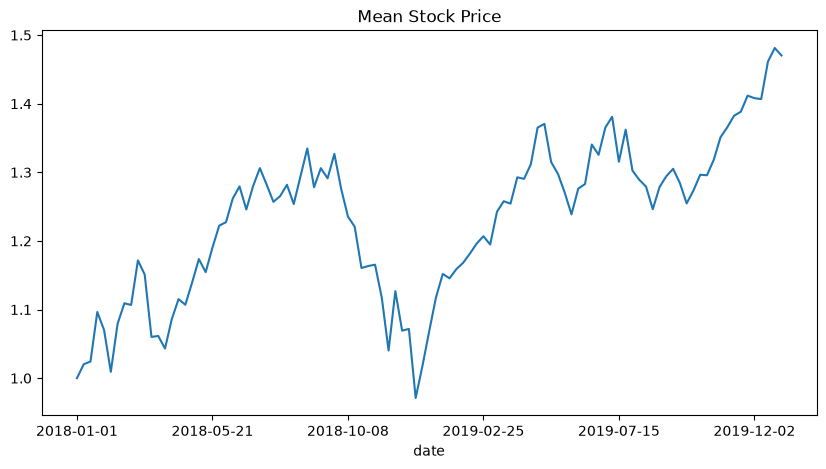

In [47]:
stocks1.mean(axis=1).plot(figsize=(10,5), title="Mean Stock Price")
plt.show()

> On December 17, 2018, U.S. stock indexes plunged sharply—with the Dow Jones Industrial Average falling 507 points (2.1%) and the S&P 500 hitting a 14-month low—driven by investor panic over slowing global economic growth, trade tensions, and an anticipated interest rate hike by the Federal Reserve. (Google AI)

### Extra

#### Changing the data type of `date` fromt `str` to `datetime`

There are advantages to converting the date from a string to Pandas' built-in data type `datetime`.

> [!note] Internally, the core data type used to represent dates and times is `datetime64`, which builds upon NumPy's underlying datetime architecture


We use the funcation [`pd.to_datetime()`](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html) to convert the column.

In [113]:
stocks_fixed = stocks.copy()                                # Make a copy of the dataframe so as not to affect the original
stocks_fixed['date'] = pd.to_datetime(stocks_fixed['date']) # Apply the conversion function
stocks_fixed = stocks_fixed.set_index('date')               # Make the data column the index
stocks_fixed

,GOOG,AAPL,AMZN,FB,NFLX,MSFT
date,,,,,,
2018-01-01,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2018-01-08,1.018172,1.011943,1.061881,0.959968,1.053526,1.015988
2018-01-15,1.032008,1.019771,1.053240,0.970243,1.049860,1.020524
2018-01-22,1.066783,0.980057,1.140676,1.016858,1.307681,1.066561
2018-01-29,1.008773,0.917143,1.163374,1.018357,1.273537,1.040708
...,...,...,...,...,...,...
2019-12-02,1.216280,1.546914,1.425061,1.075997,1.463641,1.720717
2019-12-09,1.222821,1.572286,1.432660,1.038855,1.421496,1.752239
2019-12-16,1.224418,1.596800,1.453455,1.104094,1.604362,1.784896


Note how the index is now a [`DataTimeIndex`](https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html).

In [110]:
stocks_fixed.index

DatetimeIndex(['2018-01-01', '2018-01-08', '2018-01-15', '2018-01-22',
               '2018-01-29', '2018-02-05', '2018-02-12', '2018-02-19',
               '2018-02-26', '2018-03-05',
               ...
               '2019-10-28', '2019-11-04', '2019-11-11', '2019-11-18',
               '2019-11-25', '2019-12-02', '2019-12-09', '2019-12-16',
               '2019-12-23', '2019-12-30'],
              dtype='datetime64[us]', name='date', length=105, freq=None)

See the difference in how the x axis and the lines are displayed.

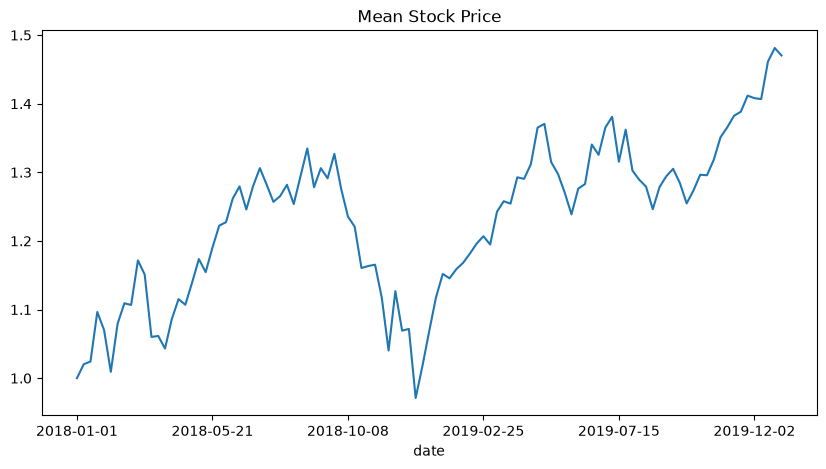

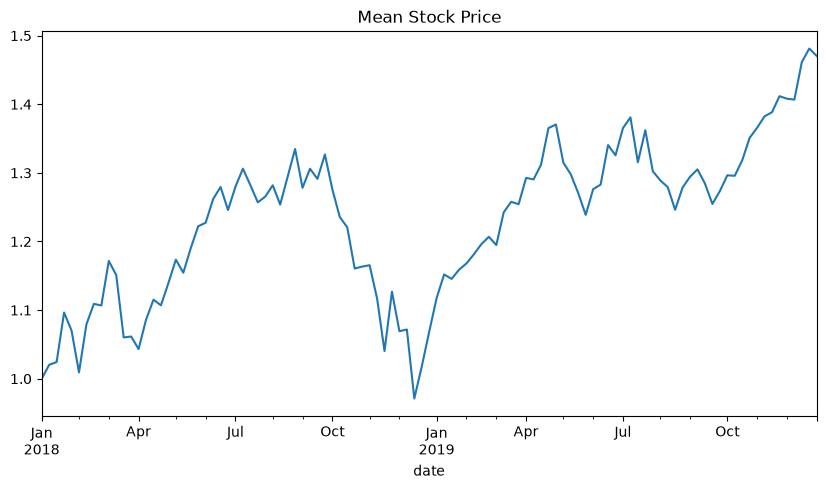

In [111]:
stocks1.mean(axis=1).plot(figsize=(10,5), title="Mean Stock Price")
plt.show()
stocks_fixed.mean(axis=1).plot(figsize=(10,5), title="Mean Stock Price")
plt.show()

We can easily convert the index from days to months using one of Pandas' datetime methods.

In [104]:
stocks_fixed.index.to_period('M')

PeriodIndex(['2018-01', '2018-01', '2018-01', '2018-01', '2018-01', '2018-02',
             '2018-02', '2018-02', '2018-02', '2018-03',
             ...
             '2019-10', '2019-11', '2019-11', '2019-11', '2019-11', '2019-12',
             '2019-12', '2019-12', '2019-12', '2019-12'],
            dtype='period[M]', name='date', length=105)

Then we can aggregate by month.

In [105]:
stocks_monthly = stocks_fixed.groupby(stocks_fixed.index.to_period('M')).mean()
stocks_monthly

,GOOG,AAPL,AMZN,FB,NFLX,MSFT
date,,,,,,
2018-01,1.025147,0.985783,1.083834,0.993085,1.136921,1.028756
2018-02,0.983980,0.972214,1.177356,0.954482,1.327408,1.041189
2018-03,0.986439,0.986743,1.239377,0.922531,1.483618,1.047709
2018-04,0.941279,0.977120,1.223145,0.897190,1.485899,1.064270
2018-05,0.988854,1.076743,1.307615,1.001579,1.621339,1.114667
2018-06,1.030697,1.072243,1.386219,1.044969,1.851362,1.136127
2018-07,1.084367,1.108240,1.460846,1.041648,1.774751,1.198730
2018-08,1.106260,1.241286,1.563414,0.942521,1.653829,1.239681
2018-09,1.065322,1.269343,1.594666,0.873361,1.724558,1.276250


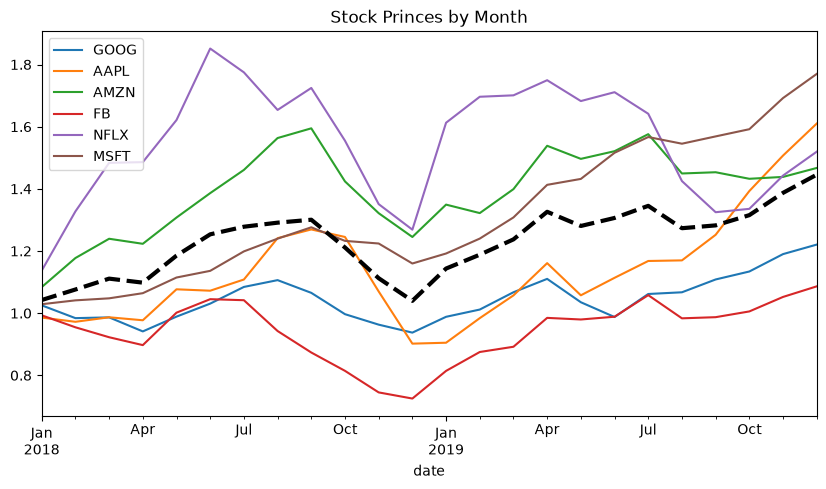

In [106]:
stocks_monthly.plot(figsize=(10,5))
stocks_monthly.mean(axis=1).plot(ls='--', lw=3, c='black')
plt.title("Stock Princes by Month")
plt.show()

#### Annotating 

Here is how you can annotate the graph to highlight the day of the big dip.

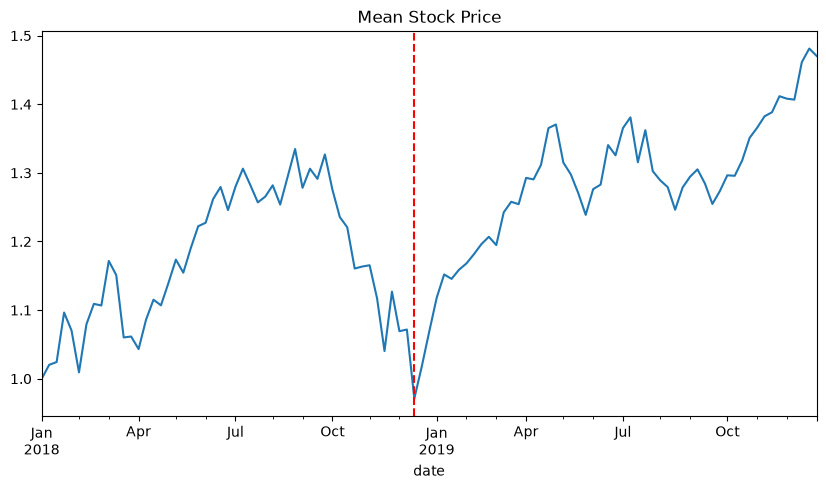

In [108]:
# Grab the axes object that plot returns
ax = stocks_fixed.mean(axis=1).plot(figsize=(10,5), title="Mean Stock Price")

# Get the date on which the line is lowest
min_date = stocks_fixed.mean(axis=1).idxmin() # idxmin gets the index for the minimum value

# Print the line 
ax.axvline(min_date, ls='--', c='red') # axvline draws a verticle line

# Show it
plt.show()

> Wall Street collapsed on Friday following investors' concerns of an impending global economic slowdown. A series of weaker-than-expected economic reports from China and European Union raised eyebrows of several market participants. All three major stock indexes closed in the red. For the week also, these indexes ended in negative territory.
>
> "Stock Market News For Dec 17, 2018", [Yahoo Finance](https://finance.yahoo.com/news/stock-market-news-dec-17-143002332.html)